# Proceso de Selección de Variables

## Librerías y Configuración

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)


In [9]:
df = pd.read_csv("../data/df_final.csv")

TARGET = "readmission_30d"

numeric_cols = df.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c != TARGET]

cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

C:\Users\Yepes Zuleta\AppData\Local\Temp\ipykernel_19012\3895594676.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


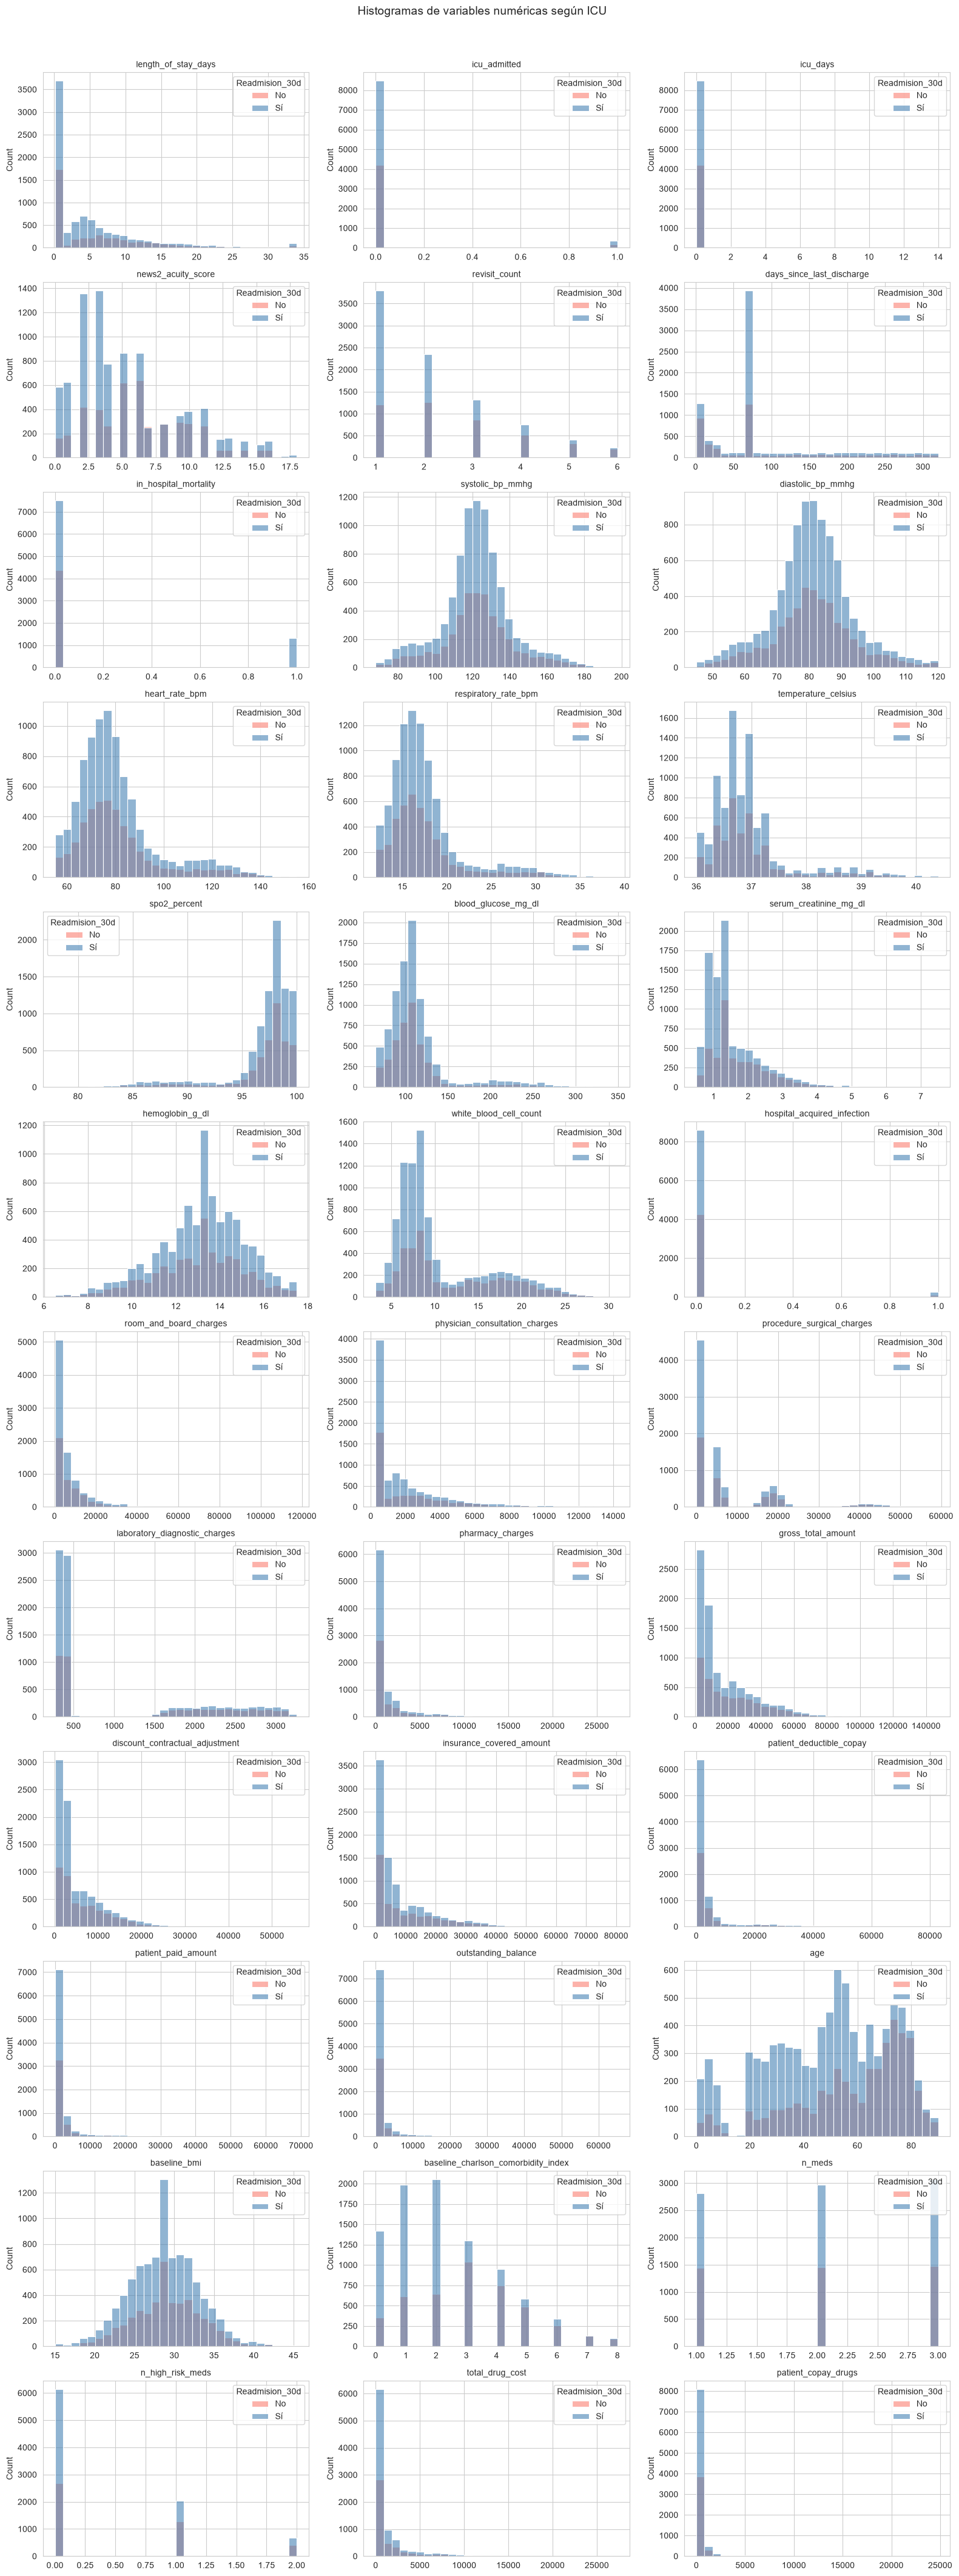

In [10]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, 
                 palette={0: "steelblue", 1: "salmon"},
                 alpha=0.6, ax=axes[i], kde=False)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].legend(title="Readmision_30d", labels=["No", "Sí"])

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Histogramas de variables numéricas según ICU", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

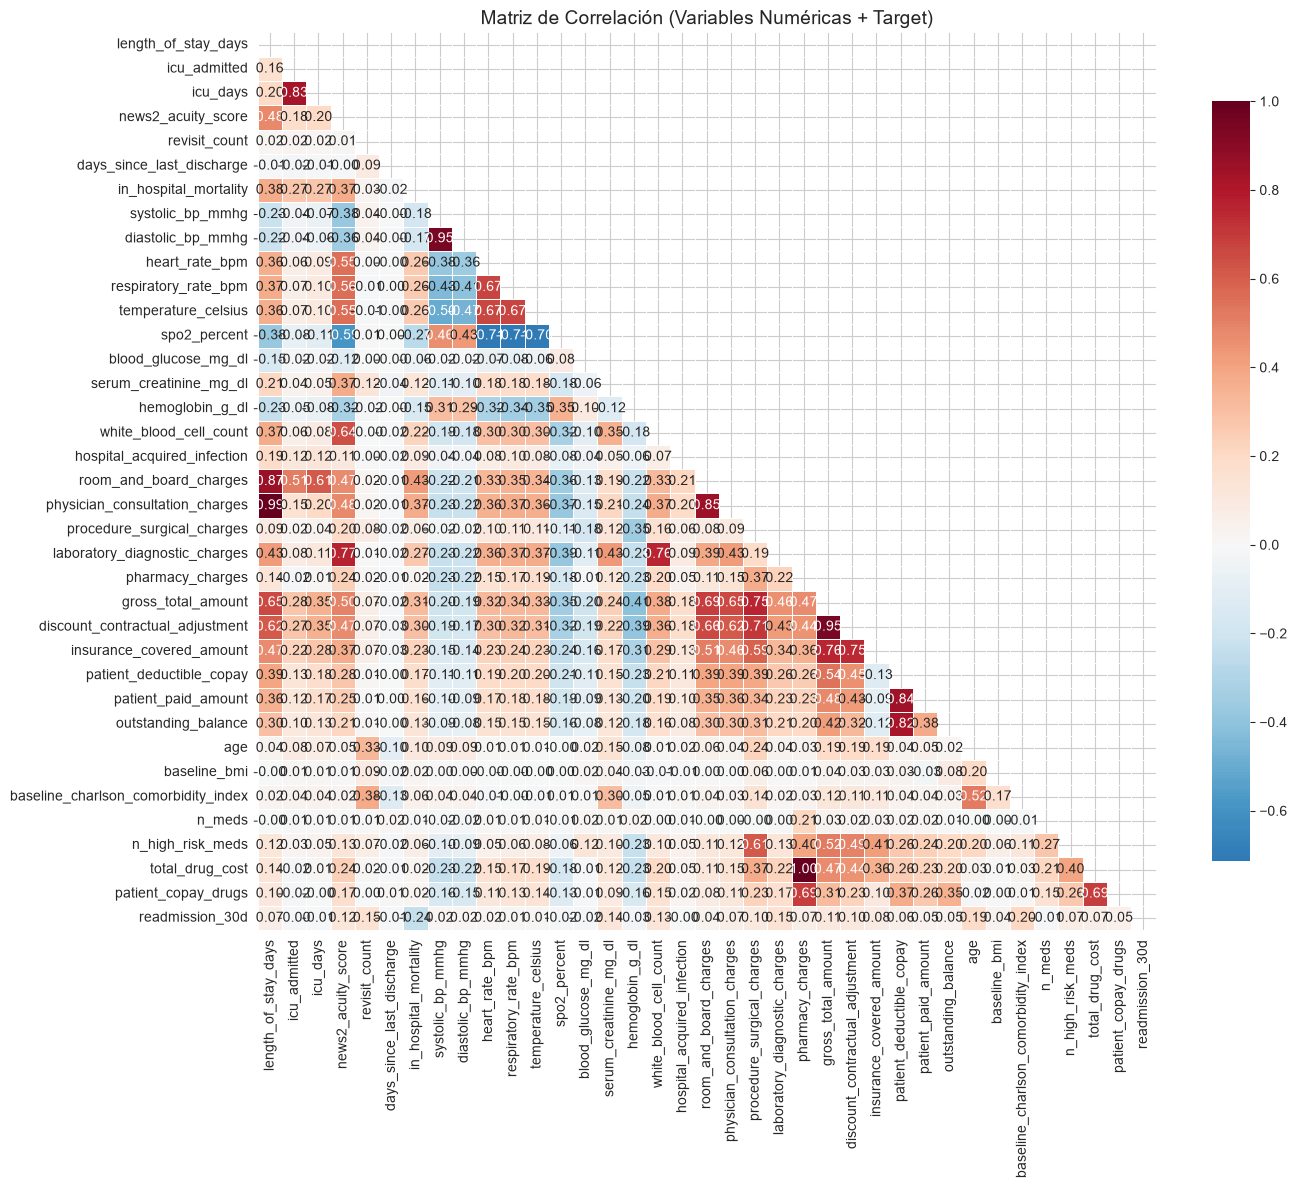

In [11]:
corr = df[numeric_cols + [TARGET]].corr()

plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))  
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title("Matriz de Correlación (Variables Numéricas + Target)", fontsize=14)
plt.tight_layout()
plt.show()

in_hospital_mortality                 -0.235
baseline_charlson_comorbidity_index    0.204
age                                    0.194
laboratory_diagnostic_charges          0.154
revisit_count                          0.151
serum_creatinine_mg_dl                 0.135
white_blood_cell_count                 0.134
news2_acuity_score                     0.120
gross_total_amount                     0.108
discount_contractual_adjustment        0.104
procedure_surgical_charges             0.096
insurance_covered_amount               0.085
n_high_risk_meds                       0.073
total_drug_cost                        0.068
pharmacy_charges                       0.068
physician_consultation_charges         0.067
length_of_stay_days                    0.067
patient_deductible_copay               0.056
patient_copay_drugs                    0.053
patient_paid_amount                    0.048
outstanding_balance                    0.045
baseline_bmi                           0.041
room_and_b

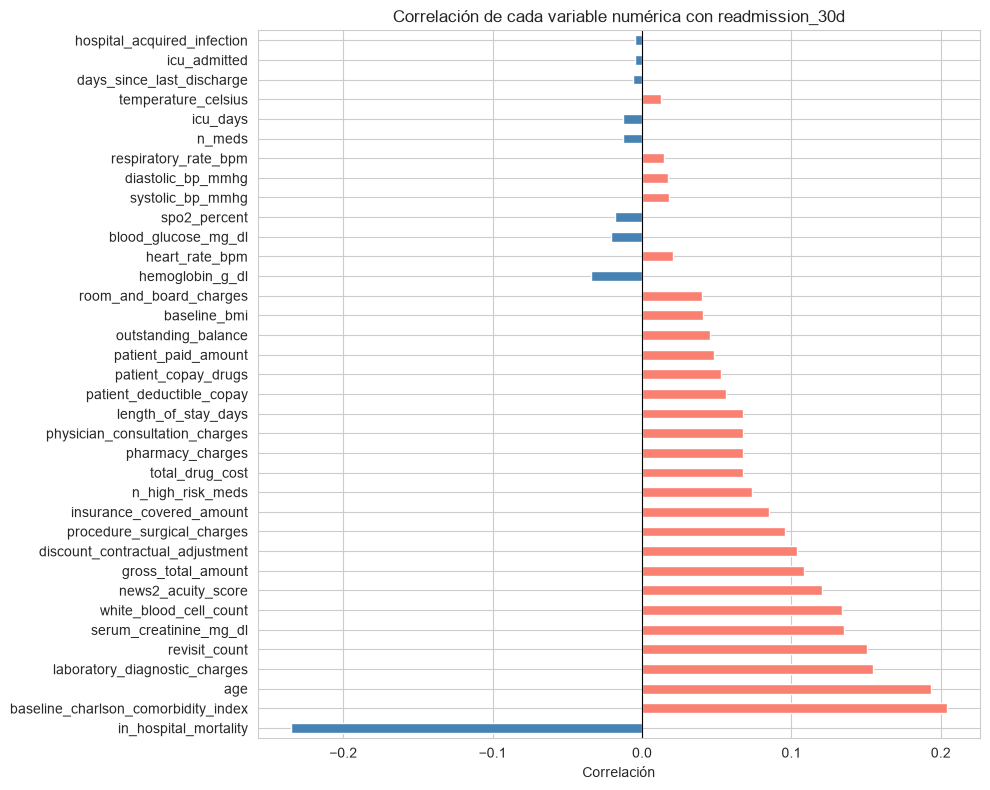

In [12]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(target_corr)

plt.figure(figsize=(10, 8))
colors = ["salmon" if v > 0 else "steelblue" for v in target_corr]
target_corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de cada variable numérica con readmission_30d")
plt.xlabel("Correlación")
plt.tight_layout()
plt.show()


--- encounter_type ---
readmission_30d      0      1
encounter_type               
Emergency       55.100 44.900
Inpatient       73.100 26.900
Outpatient      68.000 32.000


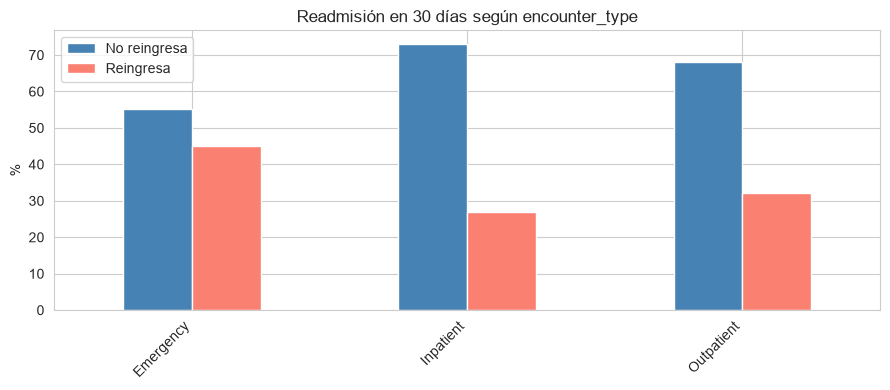


--- admission_urgency ---
readmission_30d        0      1
admission_urgency              
Elective          69.700 30.300
Emergency         60.400 39.600
Urgent            71.100 28.900


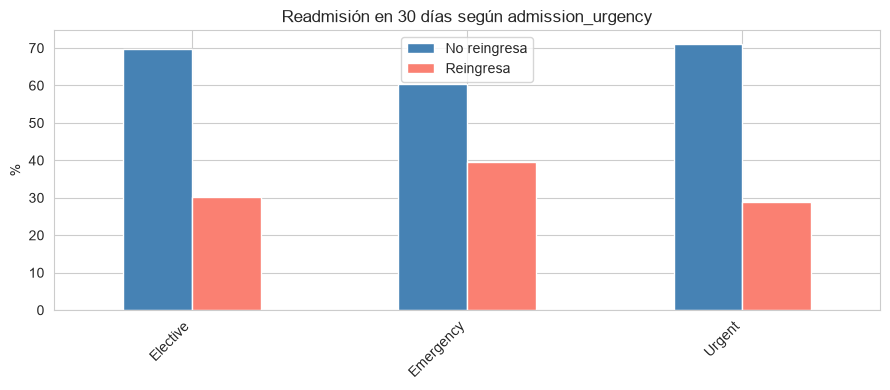


--- department ---
readmission_30d       0      1
department                    
Cardiology       62.300 37.700
General Medicine 70.200 29.800
General Surgery  72.800 27.200
ICU              58.600 41.400
Obstetrics       84.100 15.900
Oncology         55.300 44.700
Orthopedics      60.900 39.100
Pediatrics       79.300 20.700


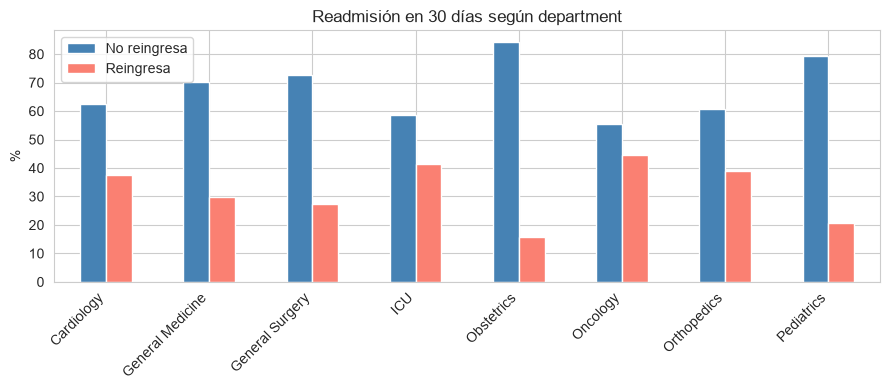


--- discharge_disposition ---
readmission_30d                0      1
discharge_disposition                  
Expired                  100.000  0.000
Home                      65.500 34.500
Left AMA                  32.800 67.200
Rehabilitation            57.400 42.600
Skilled Nursing Facility  51.700 48.300
Transferred               51.900 48.100
Unknown                   67.500 32.500


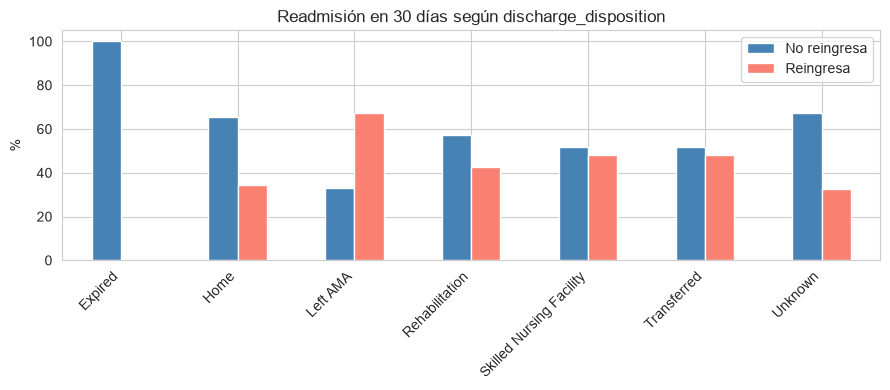


--- previous_encounter_id ---
readmission_30d             0       1
previous_encounter_id                
ENC-100001            100.000   0.000
ENC-100002              0.000 100.000
ENC-100004              0.000 100.000
ENC-100006              0.000 100.000
ENC-100007              0.000 100.000
...                       ...     ...
ENC-113207            100.000   0.000
ENC-113209              0.000 100.000
ENC-113210              0.000 100.000
ENC-113213            100.000   0.000
Unknown                75.900  24.100

[8215 rows x 2 columns]


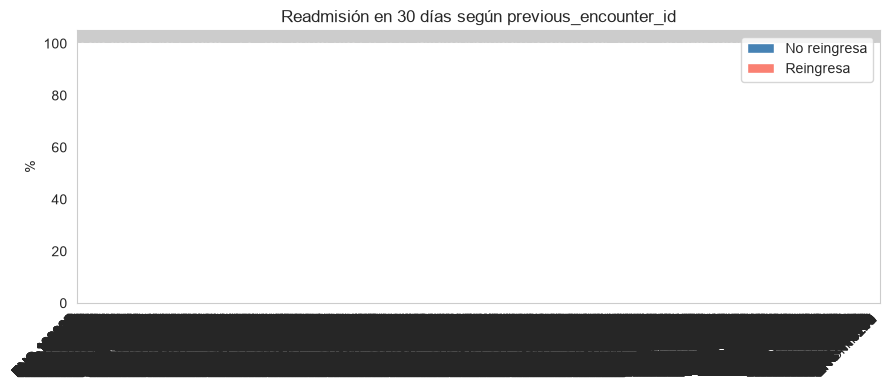


--- disease_category ---
readmission_30d       0      1
disease_category              
Cardiovascular   62.300 37.700
Endocrine        70.100 29.900
Gastrointestinal 72.800 27.200
Infectious       60.300 39.700
Musculoskeletal  65.100 34.900
Obstetrics       84.100 15.900
Oncology         55.300 44.700
Pediatrics       87.500 12.500
Renal            74.500 25.500
Respiratory      69.300 30.700
Trauma           55.300 44.700


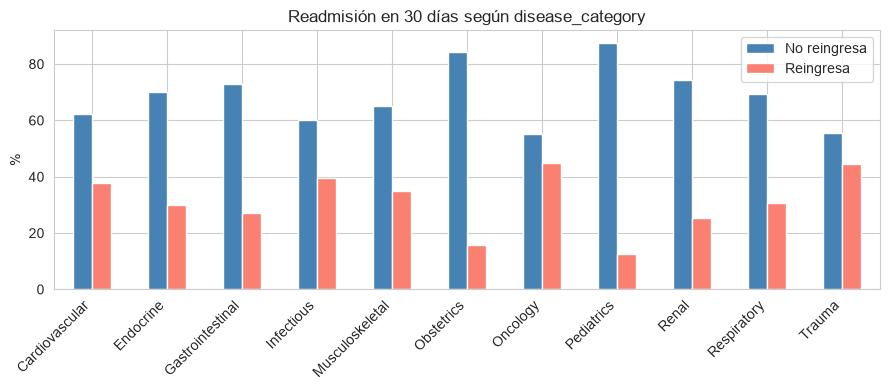


--- disease_severity ---
readmission_30d       0      1
disease_severity              
Critical         65.500 34.500
Mild             77.000 23.000
Moderate         70.300 29.700
Severe           53.300 46.700


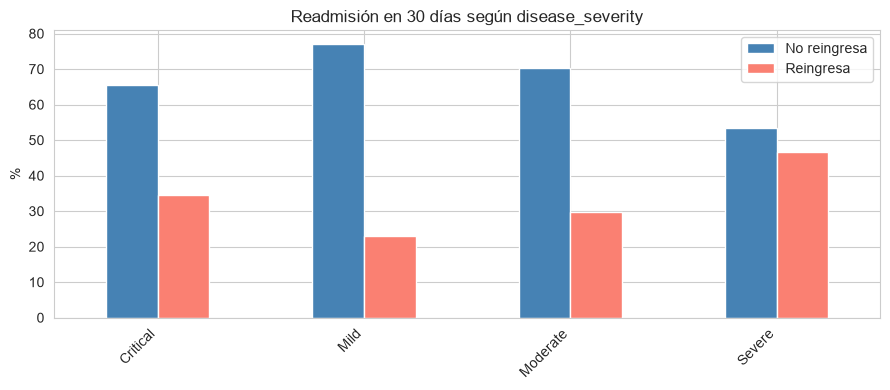


--- procedure_complexity ---
readmission_30d           0      1
procedure_complexity              
High-Complexity      55.300 44.700
Major                61.400 38.600
Minor                63.000 37.000
Moderate             67.500 32.500
Unknown              71.600 28.400


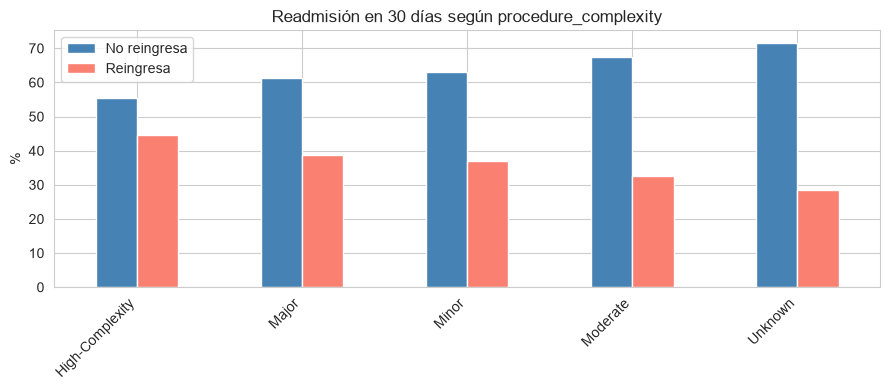


--- payment_status ---
readmission_30d      0      1
payment_status               
Paid in Full    70.700 29.300
Partial Payment 66.900 33.100


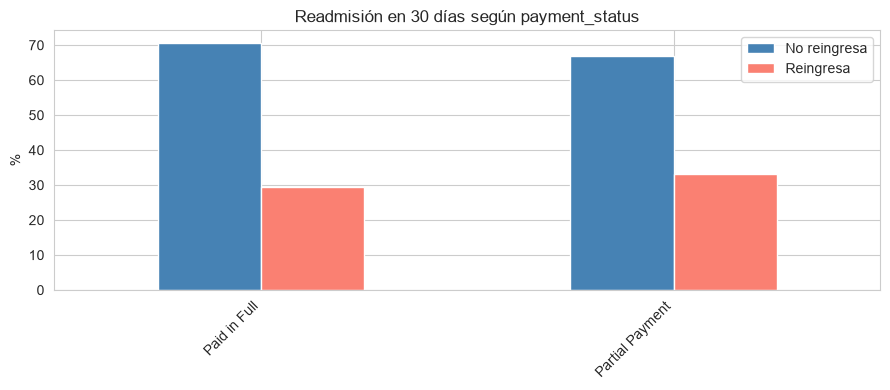


--- claim_status ---
readmission_30d                0      1
claim_status                           
Approved                  67.400 32.600
Rejected                  64.600 35.400
Self-Pay / Not Applicable 66.300 33.700


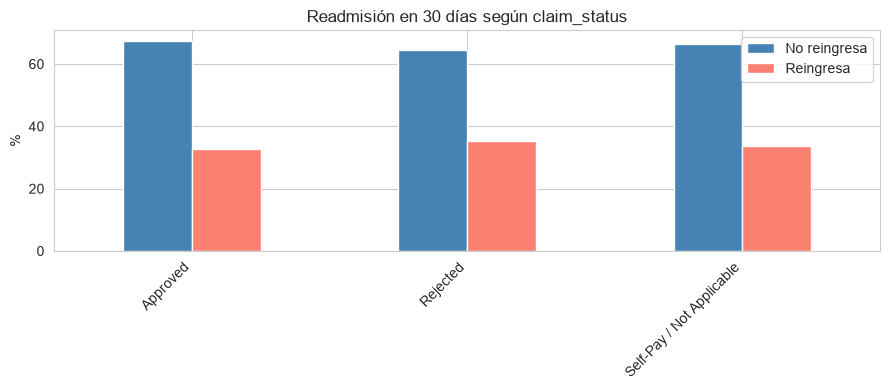


--- gender ---
readmission_30d      0      1
gender                       
Female          66.800 33.200
Male            67.100 32.900


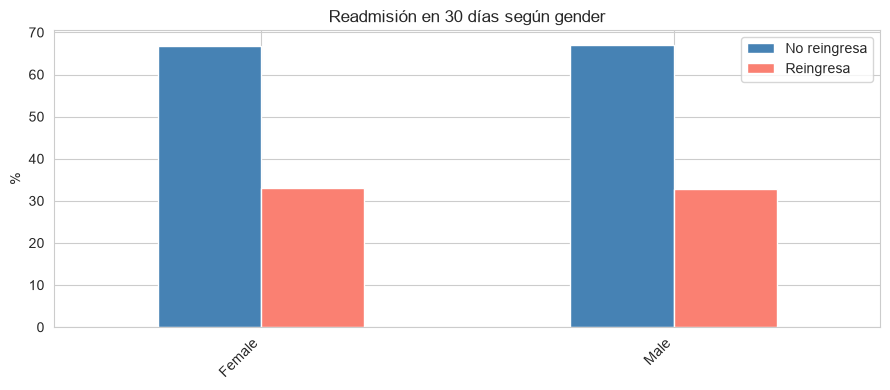


--- blood_group ---
readmission_30d      0      1
blood_group                  
A+              66.700 33.300
A-              65.100 34.900
AB+             64.200 35.800
AB-             68.400 31.600
B+              66.600 33.400
B-              62.500 37.500
O+              67.900 32.100
O-              68.200 31.800


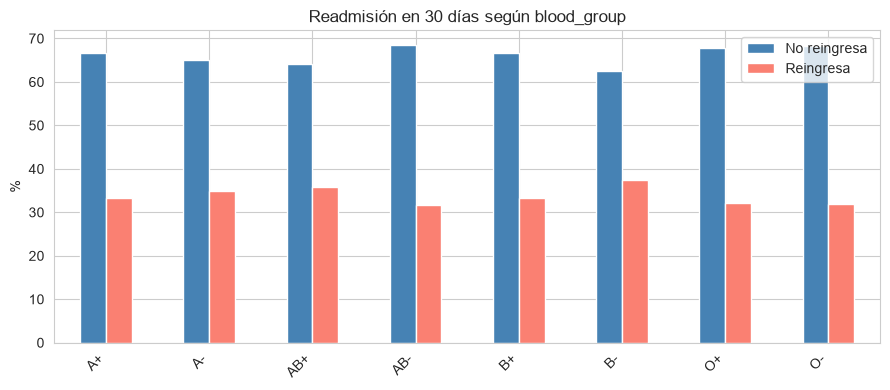


--- marital_status ---
readmission_30d      0      1
marital_status               
Divorced        66.300 33.700
Married         66.200 33.800
Single          74.500 25.500
Widowed         54.900 45.100


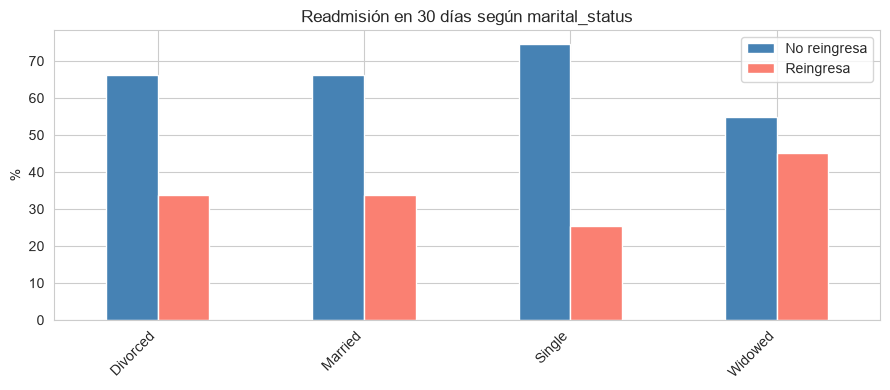


--- race_ethnicity ---
readmission_30d       0      1
race_ethnicity                
African American 67.400 32.600
Asian            67.100 32.900
Caucasian        66.300 33.700
Hispanic         70.100 29.900
Other            64.400 35.600


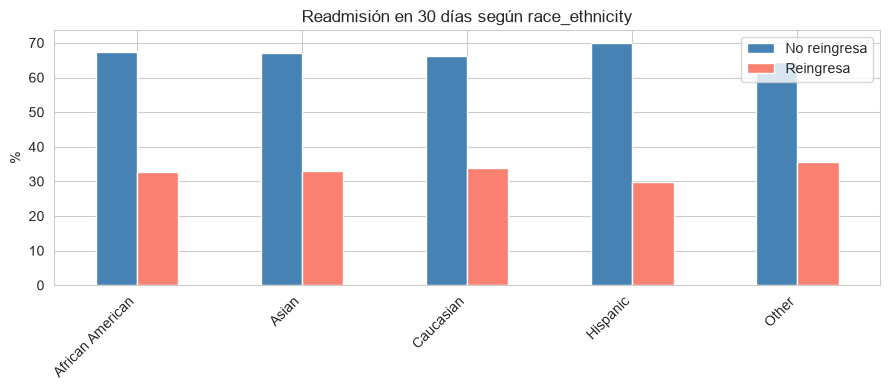


--- residential_zone ---
readmission_30d       0      1
residential_zone              
Rural            67.000 33.000
Suburban         67.200 32.800
Urban            66.900 33.100


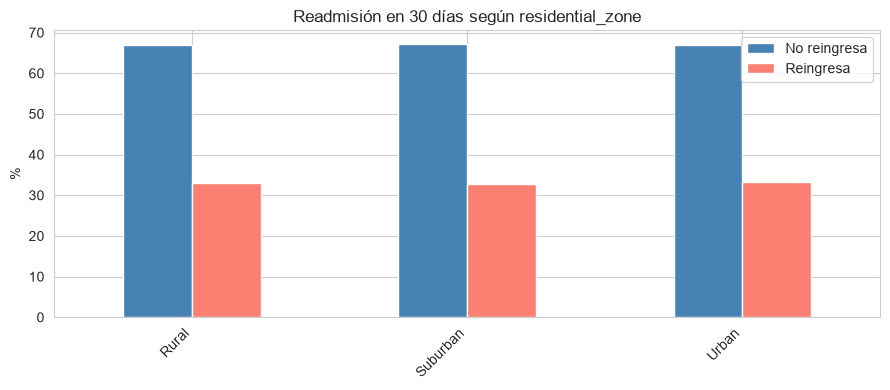


--- socioeconomic_tier ---
readmission_30d         0      1
socioeconomic_tier              
High               65.500 34.500
Low                67.000 33.000
Middle             67.700 32.300


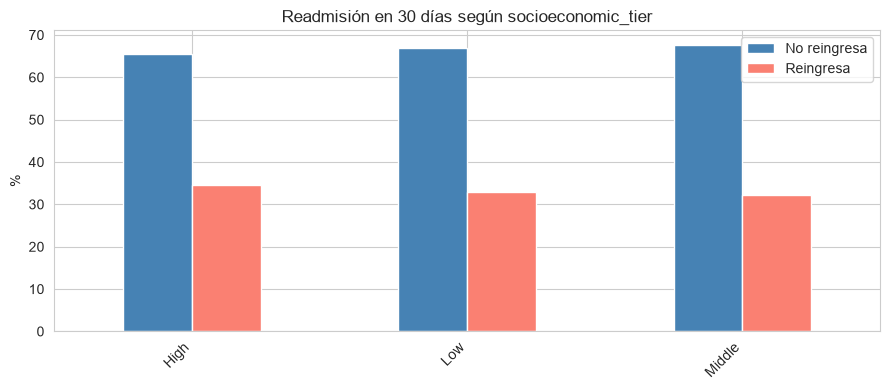


--- primary_insurance_provider ---
readmission_30d                 0      1
primary_insurance_provider              
BlueCross                  73.100 26.900
Kaiser                     78.100 21.900
Medicaid                   76.000 24.000
Medicare                   54.100 45.900
Self-Pay                   66.300 33.700
UnitedHealth               72.800 27.200


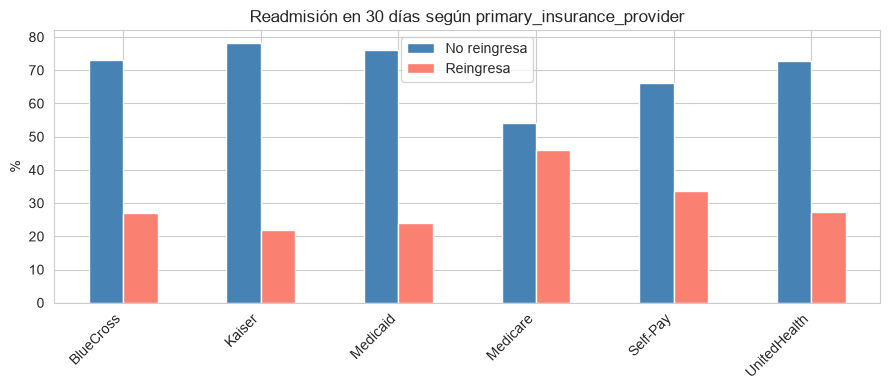


--- smoker_status ---
readmission_30d      0      1
smoker_status                
Current         64.000 36.000
Former          66.500 33.500
Never           68.000 32.000
Unknown         67.200 32.800


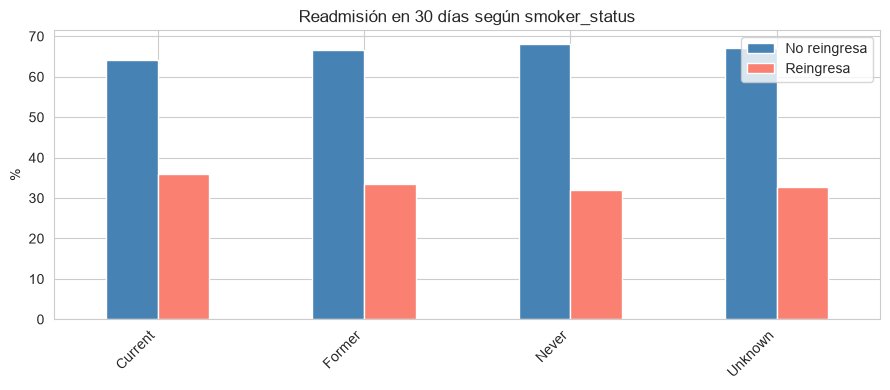

In [13]:
for col in cat_cols:
    print(f"\n--- {col} ---")
    ct = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
    print(ct.round(1))
    
    # Gráfico
    fig, ax = plt.subplots(figsize=(9, 4))
    ct.plot(kind="bar", stacked=False, color=["steelblue", "salmon"], ax=ax)
    ax.set_title(f"Readmisión en 30 días según {col}")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.legend(["No reingresa", "Reingresa"])
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## Selección Final de Variables para el Modelo de Mortalidad Hospitalaria

Despues del análisis exploratorio de las variables se seleccionaron las siguientes de acuerdo a su correlación y distribución con la variable objetivo:

numeric_features = [
    "age",
    "baseline_bmi",
    "baseline_charlson_comorbidity_index",
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "n_meds",
    "n_high_risk_meds",
    "serum_creatinine_mg_dl",
    "hemoglobin_g_dl",
    "spo2_percent",
    "respiratory_rate_bpm",
    "heart_rate_bpm",
    "systolic_bp_mmhg",
    "white_blood_cell_count",
    "blood_glucose_mg_dl"
]

categoric_features = [
    "discharge_disposition",
    "disease_category",
    "disease_severity",
    "department",
    "admission_urgency",
    "encounter_type",
    "primary_insurance_provider",
    "socioeconomic_tier",
    "residential_zone",
    "smoker_status",
    "gender",
    "procedure_complexity",
    "hospital_acquired_infection"   
]


### Criterios generales de selección

1. **Relevancia clínica**: Factores de riesgo
2. **Poder discriminativo**: Mostraban separación importante en los histogramas
3. **Disponibilidad temporal**: Variables en el ingreso o en la estancia de la hospitalización

Este conjunto de **33 variables** (19 numéricas + 14 categóricas)